In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('/content/AirPassengers.csv')
df

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [4]:
df.shape

(144, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [6]:
df.isnull().sum()

,0
Month,0
#Passengers,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.rename(columns = {'Month':'month','#Passengers':'passengers'}, inplace=True)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   month       144 non-null    object
 1   passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [10]:
df['month'] = pd.to_datetime(df['month'])

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   month       144 non-null    datetime64[ns]
 1   passengers  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.4 KB


In [12]:
df.set_index("month", inplace = True)

In [13]:
df

,passengers
month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


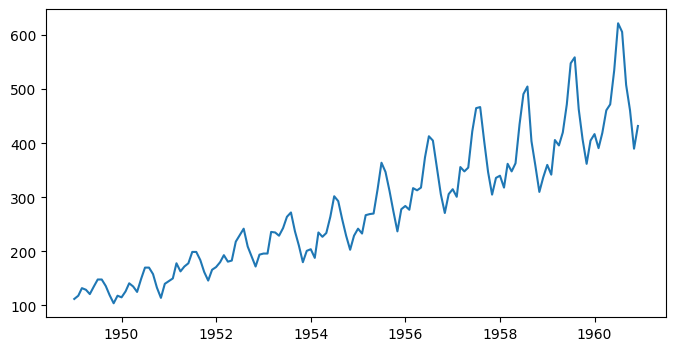

In [14]:
plt.figure(figsize = (8,4))
plt.plot(df)
plt.show()

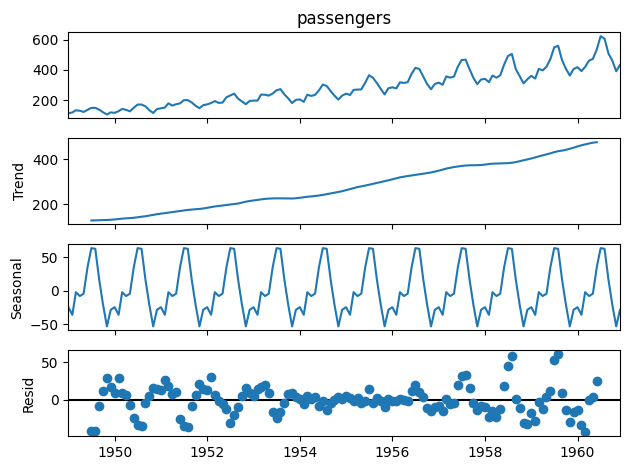

In [15]:
from statsmodels.tsa.seasonal import seasonal_decompose

decompose = seasonal_decompose(df['passengers'])
decompose.plot()
plt.show()

In [16]:
from statsmodels.tsa.stattools import adfuller

In [17]:
# Null hypothesis: Data is not stationary
# Alternate hypothesis: Data is stationary
result = adfuller(df)
p_val = result[1]
p_val

0.991880243437641

In [18]:
if p_val > 0.05:
  print('Data is not stationary')
else:
  print('Data is stationary')

Data is not stationary


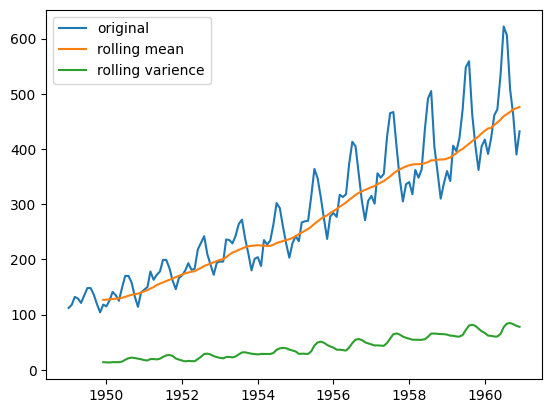

In [19]:
mean = df.rolling(window = 12).mean()
std = df.rolling(window = 12).std()

plt.plot(df,label = 'original')
plt.plot(mean, label = 'rolling mean')
plt.plot(std, label = 'rolling varience')
plt.legend(loc = 'best')
plt.show()

In [20]:
log_df = np.log(df)

In [21]:
log_df.isnull().sum()

,0
passengers,0


<Axes: xlabel='month'>

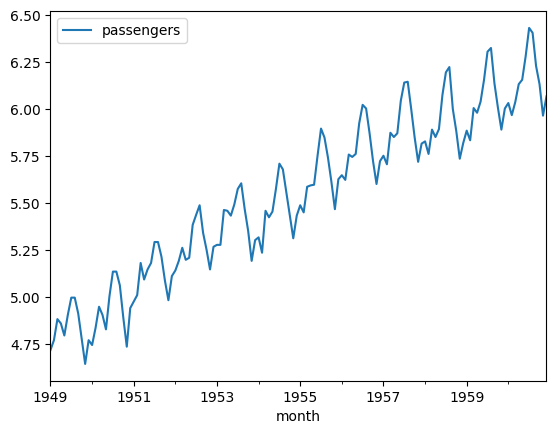

In [22]:
log_df.plot()

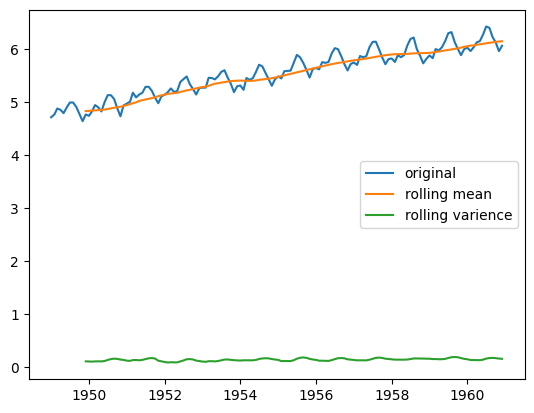

In [23]:
mean = log_df.rolling(window = 12).mean()
std = log_df.rolling(window = 12).std()

plt.plot(log_df,label = 'original')
plt.plot(mean, label = 'rolling mean')
plt.plot(std, label = 'rolling varience')
plt.legend(loc = 'best')
plt.show()

In [24]:
new_data = log_df - mean
new_data = new_data.dropna()
new_data

,passengers
month,
1949-12-01,-0.065494
1950-01-01,-0.093449
1950-02-01,-0.007566
1950-03-01,0.099416
1950-04-01,0.052142
...,...
1960-08-01,0.282363
1960-09-01,0.098235
1960-10-01,-0.009230


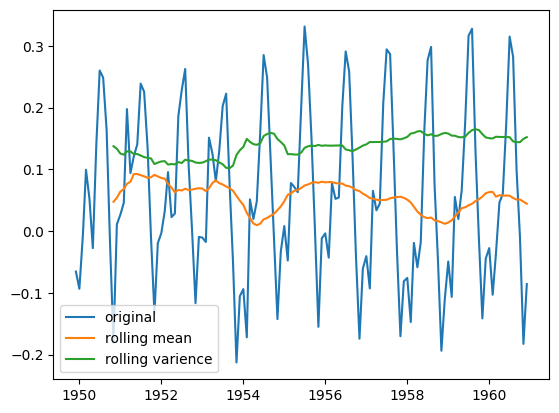

In [25]:
mean = new_data.rolling(window = 12).mean()
std = new_data.rolling(window = 12).std()

plt.plot(new_data,label = 'original')
plt.plot(mean, label = 'rolling mean')
plt.plot(std, label = 'rolling varience')
plt.legend(loc = 'best')
plt.show()

In [26]:
new_data.shape

(133, 1)

In [27]:
133 * 0.8

106.4

In [28]:
train = new_data.iloc[:106]['passengers']
test = new_data.iloc[106:]['passengers']

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

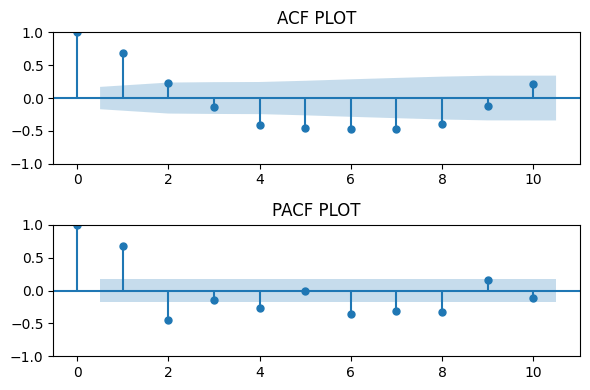

In [30]:
fig, axes = plt.subplots(2,1, figsize = (6,4))
plot_acf(new_data, lags = 10, ax = axes[0])
axes[0].set_title('ACF PLOT')

plot_pacf(new_data, lags = 10, ax = axes[1])
axes[1].set_title('PACF PLOT')

plt.tight_layout()
plt.show()

In [31]:
# p and q

# p -- AR value -- current value depends on previous value
# q -- MA value -- number of past error values used to calculate current
# I -- differencing -- integration

In [32]:
from statsmodels.tsa.arima.model import ARIMA

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


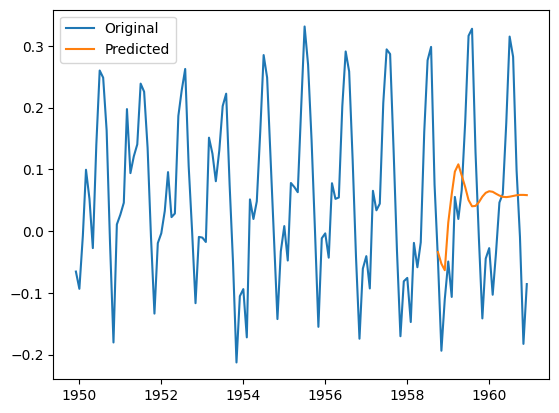

In [33]:
arima = ARIMA(train, order = (4,1,2))
arima_result = arima.fit()

new_data['predicted_arima'] = arima_result.predict(start = len(train), end = len(train) + len(test) -1, dynamic = True)

plt.plot(new_data['passengers'], label = 'Original')
plt.plot(new_data['predicted_arima'], label = 'Predicted')
plt.legend()
plt.show()

In [34]:
import itertools
from sklearn.metrics import *

p = range (0,10)
d = range (1,2)
q = range (0,8)

pdq = list(itertools.product(p,d,q))
rmse = []
order1 = []

for i in pdq:
  model = ARIMA(train, order = i)
  model_fit = model.fit()
  pred = model_fit.predict(start = len(train), end = len(train) + len(test) -1, dynamic = True)
  error = np.sqrt(mean_squared_error(test, pred))
  order1.append(i)
  rmse.append(error)

results = pd.DataFrame(index = order1, data = rmse, columns = ['RMSE'])

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

In [35]:
results.sort_values(by="RMSE", ascending = True)

,RMSE
"(8, 1, 7)",0.060793
"(9, 1, 7)",0.064993
"(9, 1, 3)",0.065136
"(9, 1, 4)",0.065268
"(9, 1, 6)",0.065729
...,...
"(2, 1, 7)",0.149920
"(0, 1, 1)",0.150150
"(2, 1, 0)",0.151556
"(3, 1, 0)",0.151889


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


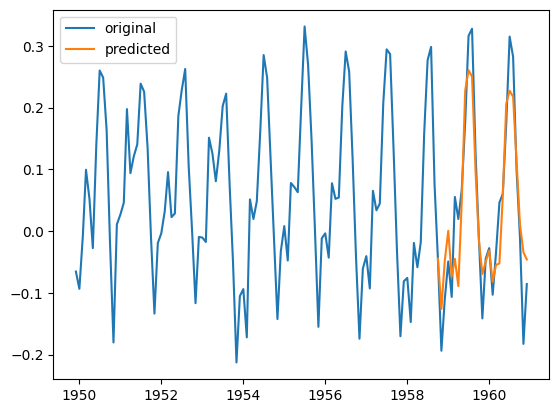

In [36]:
arima_best = ARIMA(train, order = (8,1,7))
arima_best_result = arima_best.fit()

new_data['best_arima']=arima_best_result.predict(start = len(train), end = len(train)+len(test)-1, dynamic=False)

# if you want to use the previously predicted value as an input to predict the next value then Dynamic = True

plt.plot(new_data['passengers'], label ='original')
plt.plot(new_data['best_arima'], label ='predicted')
plt.legend()
plt.show()